# Consolidado: cáncer gástrico en tres fuentes públicas

**Fuentes:** ClinicalTrials.gov (v2), openFDA (eventos adversos de capecitabina) y PubMed (E-utilities).
Los datos se descargaron el **2026-10-14** (ver `README.md` y `bitacora.md`), se guardaron crudos en `data/raw/`,
se validaron con Pydantic y se consolidaron en Parquet (`data/procesado/`). Este notebook solo **lee** esos Parquet.

**Alcance y límites, antes de leer los resultados:**
- *ClinicalTrials.gov:* los 4 347 estudios de `gastric cancer` (búsqueda en inglés; en español da casi nada).
- *openFDA:* el conteo de reacciones sale del servidor sobre **todos** los reportes de capecitabina con indicación gástrica; los 500 reportes completos son una **muestra**.
- *PubMed:* conteos por año de publicación (MeSH *Stomach Neoplasms*); **2026 está incompleto** (datos hasta el 14 de octubre).


In [1]:
import json, glob
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

P = Path("../data/procesado")
estudios = pd.read_parquet(P / "estudios.parquet")
paises = pd.read_parquet(P / "estudios_paises.parquet")
ubic = pd.read_parquet(P / "ubicaciones.parquet")
reportes = pd.read_parquet(P / "reportes.parquet")
reacc_muestra = pd.read_parquet(P / "reportes_reacciones.parquet")
reacc_servidor = pd.read_parquet(P / "reacciones_servidor.parquet")
pubmed = pd.read_parquet(P / "pubmed_por_anio.parquet")

# Total de reportes que cumplen la búsqueda en openFDA (viene en la respuesta cruda)
pag1 = json.loads(Path(sorted(glob.glob("../data/raw/openfda/*reportes*p001.json"))[0]).read_text())
TOTAL_REPORTES = pag1["respuesta"]["meta"]["results"]["total"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"estudios={len(estudios)} | reportes (muestra)={len(reportes)} de {TOTAL_REPORTES} | años PubMed={len(pubmed)}")

estudios=4347 | reportes (muestra)=500 de 5759 | años PubMed=27


## Pregunta 1 — ¿Cuántos ensayos activos hay para cáncer gástrico y dónde?

**Definición de "activo":** estado `RECRUITING`, `NOT_YET_RECRUITING`, `ACTIVE_NOT_RECRUITING` o `ENROLLING_BY_INVITATION`.
Un estudio multicéntrico cuenta una vez **por cada país** donde tiene sedes, así que la suma por país supera el número de estudios.

In [2]:
activos = estudios[estudios["activo"]]
print(f"Ensayos activos: {len(activos)} de {len(estudios)} ({len(activos)/len(estudios):.0%})")
print(activos["estado"].astype(str).value_counts().to_string())
sin_pais = (activos["n_paises"] == 0).sum()
print(f"\nActivos sin ningún país registrado: {sin_pais} ({sin_pais/len(activos):.0%}) -> quedan fuera del mapa")

Ensayos activos: 1291 de 4347 (30%)
estado
RECRUITING                 732
NOT_YET_RECRUITING         271
ACTIVE_NOT_RECRUITING      254
ENROLLING_BY_INVITATION     34

Activos sin ningún país registrado: 131 (10%) -> quedan fuera del mapa


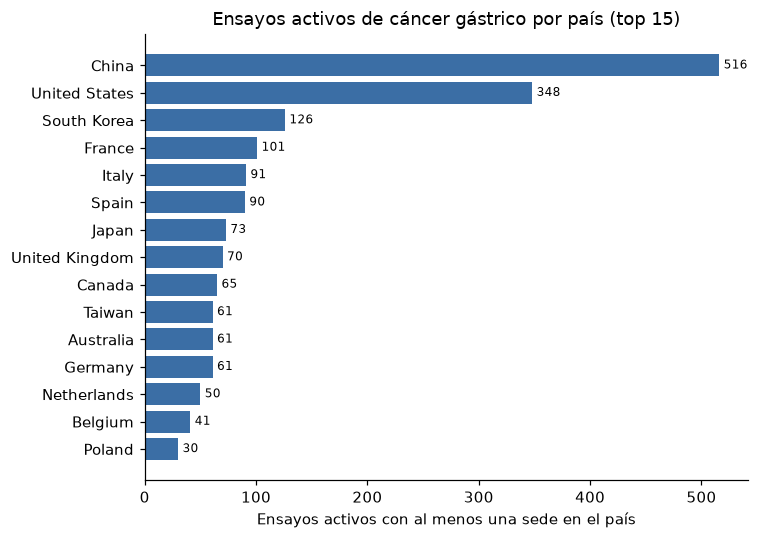

Ciudades con más ensayos activos:
ciudad
Shanghai       128
Houston        118
Beijing        114
New York       111
Seoul          109
Boston          89
Los Angeles     82
Hangzhou        81
Barcelona       80
Nashville       78


In [3]:
por_pais = (paises[paises["nct_id"].isin(activos["nct_id"])]["pais"].value_counts().head(15)[::-1])
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(por_pais.index, por_pais.values, color="#3b6ea5")
ax.set_xlabel("Ensayos activos con al menos una sede en el país")
ax.set_title("Ensayos activos de cáncer gástrico por país (top 15)")
for y, v in enumerate(por_pais.values):
    ax.text(v + 4, y, str(v), va="center", fontsize=8)
plt.tight_layout(); plt.show()

# Dónde, a nivel de ciudad (tabla creada con pd.json_normalize)
ciudades = (ubic[ubic["nct_id"].isin(activos["nct_id"])].dropna(subset=["ciudad"])
            .drop_duplicates(["nct_id", "ciudad"])["ciudad"].value_counts().head(10))
print("Ciudades con más ensayos activos:\n" + ciudades.to_string())

**Interpretación:**

- Los ensayos activos se concentran en China (516), Estados Unidos (348) y Corea del Sur (126). Es compatible con la alta carga de cáncer gástrico en Asia Oriental (cepas virulentas de *H. pylori*, como las CagA positivas, y factores dietéticos), pero los datos solo cuentan sedes registradas y **no permiten afirmar una relación causal**.
- Japón, con una de las incidencias más altas del mundo, aparece séptimo (73 estudios): ClinicalTrials.gov **no es un censo global**, y parte de la investigación japonesa se inscribe en registros nacionales.
- El liderazgo de China y Estados Unidos refleja también su infraestructura biofarmacéutica y sus centros oncológicos capaces de sostener estudios multicéntricos.

## Pregunta 2 — ¿Cuáles son los eventos adversos más reportados de capecitabina en cáncer gástrico?

Fuente: openFDA / FAERS, reportes de capecitabina con indicación gástrica. **Precaución:** son notificaciones espontáneas y **no hay denominador**
(no sabemos cuántos pacientes recibieron el fármaco), así que se puede ordenar por frecuencia pero **no estimar incidencia ni comparar con otros fármacos**.
Un reporte puede traer varias reacciones, por lo que los porcentajes no suman 100 %.

Sobre los 5759 reportes (conteo del servidor):
                                   reaccion  reportes  % de reportes
                                  DIARRHOEA       751           13.0
                                     NAUSEA       614           10.7
                                   VOMITING       547            9.5
                         DECREASED APPETITE       387            6.7
                                      DEATH       386            6.7
                                    ANAEMIA       333            5.8
PALMAR-PLANTAR ERYTHRODYSAESTHESIA SYNDROME       330            5.7
                                NEUTROPENIA       328            5.7
                        DISEASE PROGRESSION       287            5.0
                                    FATIGUE       268            4.7
                           MYELOSUPPRESSION       258            4.5
                              OFF LABEL USE       253            4.4
                           THROMBOCYTOPENIA       239   

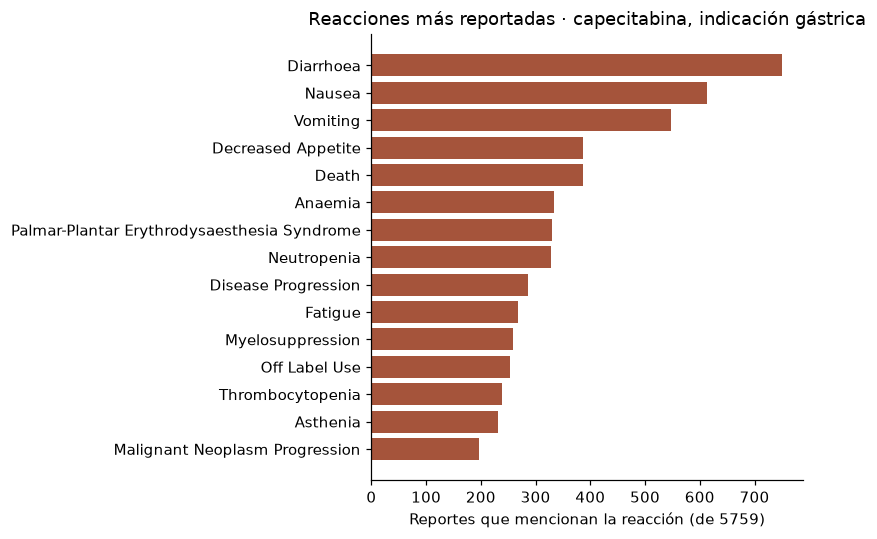

In [4]:
top = reacc_servidor.head(15).copy()
top["% de reportes"] = (top["reportes"] / TOTAL_REPORTES * 100).round(1)
print(f"Sobre los {TOTAL_REPORTES} reportes (conteo del servidor):")
print(top.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 5))
t = top[::-1]
ax.barh(t["reaccion"].str.title(), t["reportes"], color="#a5543b")
ax.set_xlabel(f"Reportes que mencionan la reacción (de {TOTAL_REPORTES})")
ax.set_title("Reacciones más reportadas · capecitabina, indicación gástrica")
plt.tight_layout(); plt.show()

In [5]:
# ¿La muestra de 500 reportes se parece al conteo completo? (comprobación, no resultado)
reacc_muestra = reacc_muestra.assign(reaccion=reacc_muestra["reaccion"].str.upper())  # el servidor devuelve MAYÚSCULAS
m = (reacc_muestra.groupby("reaccion")["id_reporte"].nunique() / len(reportes) * 100).round(1)
comp = top.set_index("reaccion").join(m.rename("% en muestra de 500")).head(10)
print(comp[["% de reportes", "% en muestra de 500"]].to_string())
print(f"\nReportes de la muestra con edad: {reportes['edad_anios'].notna().sum()} de {len(reportes)} "
      f"| edad mediana {reportes['edad_anios'].median():.0f} años (rango {reportes['edad_anios'].min():.0f}-{reportes['edad_anios'].max():.0f})")

                                             % de reportes  % en muestra de 500
reaccion                                                                       
DIARRHOEA                                             13.0                 15.8
NAUSEA                                                10.7                  8.4
VOMITING                                               9.5                 10.4
DECREASED APPETITE                                     6.7                  6.4
DEATH                                                  6.7                  4.2
ANAEMIA                                                5.8                  5.2
PALMAR-PLANTAR ERYTHRODYSAESTHESIA SYNDROME            5.7                  5.4
NEUTROPENIA                                            5.7                  7.0
DISEASE PROGRESSION                                    5.0                  3.2
FATIGUE                                                4.7                  2.6

Reportes de la muestra con edad: 384 de

**Interpretación:**

- Diarrea (13.0 %) y síndrome mano-pie (5.7 %) son las toxicidades dosis-limitantes clásicas de capecitabina; náusea y vómito suelen ser de menor severidad. Capecitabina es un profármaco del 5-FU activado en el tumor por la timidina fosforilasa: el recambio rápido del epitelio intestinal sustenta la diarrea, y el mecanismo exacto del síndrome mano-pie no está plenamente esclarecido.
- "Muerte" y "progresión de la enfermedad" aparecen entre las reacciones, pero en el cáncer gástrico avanzado suelen reflejar la enfermedad de base y no necesariamente un efecto del fármaco (límite de MedDRA y de la notificación espontánea).
- Sin el denominador de pacientes expuestos, los porcentajes son frecuencia relativa entre reportes, **no incidencia**.

## Pregunta 3 — ¿Cómo evolucionó la publicación en PubMed por año?

Los años completos (2000-2025) se usan para describir la tendencia. **2026 se muestra aparte** porque solo cubre hasta el 14 de octubre:
compararlo con un año completo parecería un descenso que no existe.

2000: 1,592 | 2010: 2,888 | 2020: 4,716 | 2025: 4,622
Máximo entre años completos: 2022 (4,836)
Crecimiento 2000 -> 2025: x2.9 | 2015 -> 2025: x1.08
2026 (parcial, hasta el 14-oct): 3,063


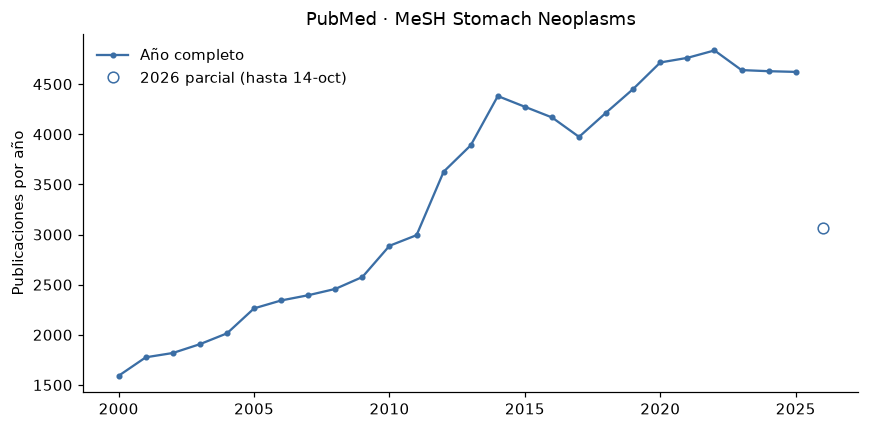

In [6]:
completos = pubmed[~pubmed["parcial"]].set_index("anio")["publicaciones"]
parcial = pubmed[pubmed["parcial"]]
c = completos
print(f"2000: {c[2000]:,} | 2010: {c[2010]:,} | 2020: {c[2020]:,} | 2025: {c[2025]:,}")
print(f"Máximo entre años completos: {c.idxmax()} ({c.max():,})")
print(f"Crecimiento 2000 -> 2025: x{c[2025]/c[2000]:.1f} | 2015 -> 2025: x{c[2025]/c[2015]:.2f}")
print(f"2026 (parcial, hasta el 14-oct): {int(parcial['publicaciones'].iloc[0]):,}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(completos.index, completos.values, marker="o", ms=3, color="#3b6ea5", label="Año completo")
ax.plot(parcial["anio"], parcial["publicaciones"], marker="o", ms=7, mfc="white", color="#3b6ea5", ls="none",
        label="2026 parcial (hasta 14-oct)")
ax.set_ylabel("Publicaciones por año"); ax.set_title("PubMed · MeSH Stomach Neoplasms")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Interpretación:**

- Hubo un crecimiento de ×1.52 entre 2010 y 2014 (2 888 a 4 381) y una meseta desde entonces: caída a 3 974 en 2017, recuperación hasta el máximo de 4 836 en 2022 y unos 4 630 entre 2023 y 2025.
- La meseta no se explica solo por el auge de la inmunoterapia o las terapias dirigidas, porque el MeSH *Stomach Neoplasms* abarca la enfermedad completa sea cual sea el enfoque; podría reflejar la maduración del campo o cambios de terminología.
- 2026 (3 063 hasta octubre) es un año parcial. El retraso en la asignación de MeSH a los artículos recientes podría explicar que quede por debajo de lo esperable para tres cuartos de año.

## Limitaciones generales
- Los resultados son una **fotografía del 2026-10-14**: las tres bases cambian a diario.
- ClinicalTrials.gov: 376 estudios (131 de los activos) no tienen país y no aparecen en el análisis geográfico.
- openFDA: sin denominador; notificación espontánea; la muestra de 500 reportes no es aleatoria.
- PubMed: el conteo por año depende del término MeSH elegido y de la fecha de publicación (`[dp]`), que incluye artículos en línea con número impreso del año siguiente.